<a href="https://colab.research.google.com/github/odoalawaye/Pytorch-Tutorial/blob/main/FrothFloat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

**Set random seed for reproducibility**

In [51]:
torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# 1. Define the Neural Network (The Surrogate)
# ========================================== **bold text**

In [52]:
class FlotationPINN(nn.Module):
  def __init__(self):
    super(FlotationPINN, self).__init__()
    # Input: time (t), Output: Recovery R(t)
    self.net = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
    )

  def forward(self, t):
    return self.net(t)

# ==========================================
# 2. Define the Physics Residual Loss
# ========================================== **bold text**

In [53]:
def physics_loss_fn(model, t_collocation, k=1.5, R_max=0.90):
  """
  Computes the residual of the first-order flotation kinetic ODE:
  dR/dt - k * (R_max - R) = 0
  """
  t_collocation.requires_grad_(True)
  R_pred = model(t_collocation)
  # Compute first derivative dR/dt using automatic differentiation
  dR_dt = torch.autograd.grad(
  outputs=R_pred,
  inputs=t_collocation,
  grad_outputs=torch.ones_like(R_pred),
  create_graph=True,
  retain_graph=True,
  only_inputs=True
  )[0]
  # Physics residual equation
  residual = dR_dt - k * (R_max - R_pred)
  # Mean Squared Error of the physics residual
  loss_physics = torch.mean(residual**2)
  return loss_physics

# ==========================================
# 3. Training Setup & Data Generation
# ========================================== **bold text**

In [54]:
model = FlotationPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=00.1)

**Generate synthetic measured" data points (sparse observations with some noise)**

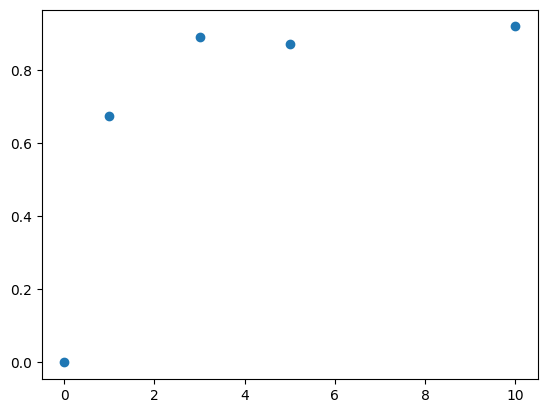

In [55]:
t_data = torch.tensor([[0.0], [1.0], [3.0], [5.0], [10.0]], dtype=torch.float32)
# True analytical solution for simulation: R(t) = R_max * (1 - exp(-k*t))
k_true, R_max_true = 1.5, 0.90
R_data = R_max_true * (1.0 - torch.exp(-k_true * t_data)) + 0.02 * torch.randn_like(t_data)
plt.plot(t_data.numpy(), R_data.numpy(), 'o')

# Generate collocation points (where physics laws are enforced across the domain)

In [56]:
t_collocation = torch.linspace(0.0, 10.0, 100).view(-1, 1)

# ==========================================
# 4. Training Loop
# ==========================================

In [57]:
epochs = 2000
for epoch in range(epochs):
  optimizer.zero_grad()
  # Data loss (MSE on available lab/plant measurements)
  R_pred_data = model(t_data)
  loss_data = torch.mean((R_pred_data - R_data)**2)
  # Physics loss (MSE on the governing kinetic differential equation)
  loss_physics = physics_loss_fn(model, t_collocation, k=k_true, R_max=R_max_true)
  # Total loss (combining data and physics constraints)
  # Weighting factors can be adjusted based on data confidence
  alpha = 1.0 # Weight for data loss
  beta = 0.2 # Weight for physics loss
  loss_total = (alpha * loss_data) + (beta * loss_physics)
  loss_total.backward()
  optimizer.step()
  if (epoch + 1) % 400 == 0:
    print(f"Epoch [{epoch+1}/{epochs}] | Total Loss: {loss_total.item():.5f} | Data Loss: {loss_data.item():.5f} | Physics Loss: {loss_physics.item():.5f}")

Epoch [400/2000] | Total Loss: 0.00012 | Data Loss: 0.00004 | Physics Loss: 0.00040
Epoch [800/2000] | Total Loss: 0.00012 | Data Loss: 0.00004 | Physics Loss: 0.00038
Epoch [1200/2000] | Total Loss: 0.00029 | Data Loss: 0.00026 | Physics Loss: 0.00019
Epoch [1600/2000] | Total Loss: 0.00012 | Data Loss: 0.00004 | Physics Loss: 0.00039
Epoch [2000/2000] | Total Loss: 0.00011 | Data Loss: 0.00003 | Physics Loss: 0.00038


# ==========================================
# 5. Evaluation and Visualization
# ==========================================

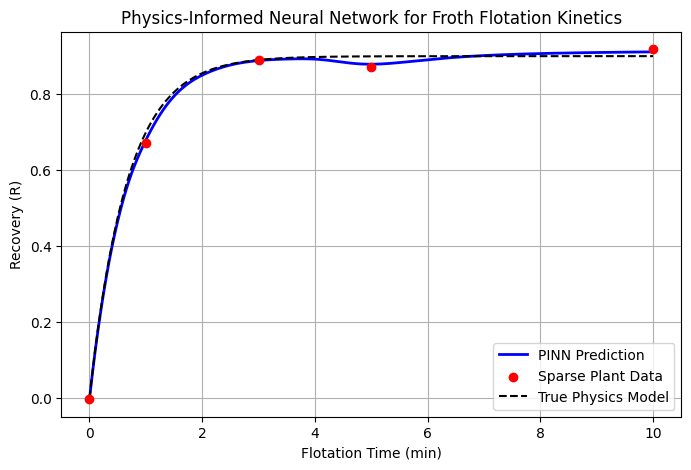

In [58]:
t_test = torch.linspace(0.0, 10.0, 200).view(-1, 1)
with torch.no_grad():
  R_pred = model(t_test)
  # Plot results
  plt.figure(figsize=(8, 5))
  plt.plot(t_test.numpy(), R_pred.numpy(), label="PINN Prediction", color="blue", linewidth=2)
  plt.scatter(t_data.numpy(), R_data.numpy(), label="Sparse Plant Data", color="red", zorder=5)
  plt.plot(t_test.numpy(), R_max_true * (1 - np.exp(-k_true * t_test.numpy())), label="True Physics Model", linestyle="--", color="black")
  plt.xlabel("Flotation Time (min)")
  plt.ylabel("Recovery (R)")
  plt.title("Physics-Informed Neural Network for Froth Flotation Kinetics")
  plt.legend()
  plt.grid(True)
  plt.show()